In [5]:
import torch
import clip
from PIL import Image
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("RN50", device=device)

In [10]:
img_paths = [
    r"C:\Users\癌坤\Desktop\task5\cat.jpg",
    r"C:\Users\癌坤\Desktop\task5\car.jpg",
    r"C:\Users\癌坤\Desktop\task5\mountain.jpg",
    r"C:\Users\癌坤\Desktop\task5\coffee.jpg"
]

images = []
for path in img_paths:
    img = Image.open(path).convert("RGB")
    img = preprocess(img)
    images.append(img)

image_input = torch.stack(images).to(device)


Task was destroyed but it is pending!
task: <Task pending name='Task-193' coro=<_async_in_context.<locals>.run_in_context() done, defined at D:\conda_envs\ai\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-194' coro=<Kernel.shell_main() running at D:\conda_envs\ai\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at D:\conda_envs\ai\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
D:\conda_envs\ai\Lib\site-packages\PIL\Image.py:459: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  from . import PpmImagePlugin
Task was destroyed but it is pending!
task: <Task pending name='Task-194' coro=<Kernel.shell_main() running at D:\conda_envs\ai\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


In [14]:
texts = [
    "a photo of an orange cat",
    "a photo of a red car",
    "a photo of a mountain",
    "a photo of a cup of coffee"
]
text_tokens = clip.tokenize(texts).to(device)


In [15]:
with torch.no_grad():
    image_features = model.encode_image(image_input)
    text_features = model.encode_text(text_tokens)

In [16]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)

In [17]:
print("图像特征shape：", image_features.shape)
print("文本特征shape：", text_features.shape)

图像特征shape： torch.Size([4, 1024])
文本特征shape： torch.Size([4, 1024])


In [18]:
similarity_matrix = (image_features @ text_features.T).cpu().numpy()
print("4×4相似度矩阵：")
print(similarity_matrix)

4×4相似度矩阵：
[[0.1896  0.1177  0.1456  0.1428 ]
 [0.1344  0.171   0.1454  0.1147 ]
 [0.0942  0.1439  0.1886  0.12036]
 [0.1289  0.1174  0.1584  0.2462 ]]


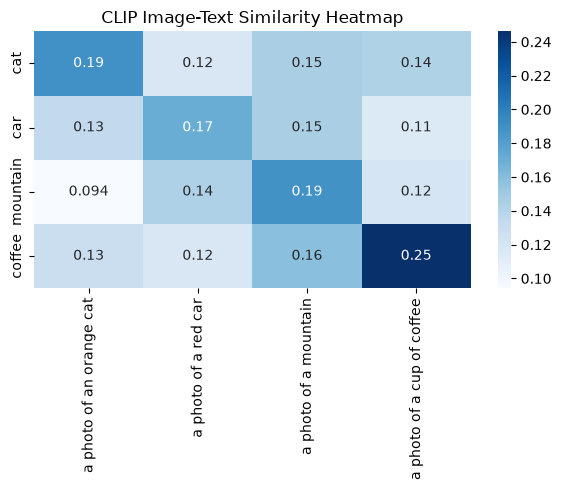

In [19]:
plt.figure(figsize=(6,5))
sns.heatmap(similarity_matrix, annot=True, cmap="Blues",
            xticklabels=texts,
            yticklabels=["cat","car","mountain","coffee"])
plt.title("CLIP Image-Text Similarity Heatmap")
plt.tight_layout()
plt.show()